# KL-Anchor Validation vs Pure Population-$\beta$ Loss (`jaredpalmer/kev-0.8b`)

Tests whether adding forward $\mathrm{KL}(p_0 \,\|\, p_\theta)$ toward the frozen base model stabilizes pure table-only training on `wu2025` (`8` fitted OLS slopes, `0` respondent choices $y$):

$$\mathcal{L}(\theta) = \lambda\,\widehat{\mathcal{L}}_{\text{pop-}\beta}^{\text{split}}(p_\theta, \beta^*_{\text{Wu}}) + \alpha\,\mathrm{KL}(p_0 \,\|\, p_\theta), \qquad \lambda = 1.0$$

Because Wu's 8 slopes constrain only an 8-dimensional projection of the model's choice probabilities across `18,591` tasks, the remaining directions are unconstrained when $\alpha = 0$. In `v13` (`α = 0`, `lr = 1e-5`), `kriner2026/beta_mse` improved (`0.01775 -> 0.00396`), while `wu2025` `monitor_kl` drifted (`0.83 -> 2.27`) and held-out `grummon2025/beta_mse` degraded (`0.00546 -> 0.00844` at `best.pt`, spiking to `0.0985` at step 500).

| Run Folder (`runs/kl_anchor_800m/`) | $\lambda$ | $\alpha$ (`kl_anchor_alpha`) | Peak LR | Epochs | Steps | Role |
|---|---:|---:|---:|---:|---:|---|
| `wu_table_alpha=0` | 1.0 | `0.0` | `1e-5` | 3 | 1,395 | Pure split population-$\beta$ baseline (no KL anchor) |
| `wu_table_alpha=0.02` | 1.0 | `0.02` | `1e-5` | 3 | 1,395 | Light KL anchor |
| `wu_table_alpha=0.1` | 1.0 | `0.10` | `1e-5` | 3 | 1,395 | Moderate KL anchor |
| `wu_table_alpha=0.5` | 1.0 | `0.50` | `1e-5` | 3 | 1,395 | Strong KL anchor |

All outputs are saved under `runs/kl_anchor_800m/` in the paper folder so `runs/kev-0.8b/` remains untouched for `01-train-paper-800m.ipynb`. Checkpoint selection uses `BEST_METRIC = "kriner2026/beta_mse"`; `grummon2025` is held out for evaluation only.

In [ ]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "models"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and models/ at or above {Path.cwd()}")

PAPER_DIR = CODE_DIR / "papers" / "beta-loss"
SRC_DIR = PAPER_DIR / "src"
if not (SRC_DIR / "paper_beta").is_dir():
    raise RuntimeError(f"`paper_beta` package not found in {SRC_DIR}")

# Run from `code/` so data loaders and shared disk caches resolve identically to all beta-training notebooks
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_train import runs as run_store
from beta_train.diagnostics import find_max_micro_chunk
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import set_checkpointing, snapshot_trainable
from beta_train.validation import PopulationValidator, validate_all_cached, validation_metrics_frame
from paper_beta import (
    PaperTrainConfig,
    extract_step0_from_run_dir,
    load_paper_run,
    run_paper_training,
)
from paper_beta.trainer import paper_steps_per_epoch

# Shared disk cache for tokenized items and untrained step-0 validation; isolated run directory for alpha validation
CACHE_DIR = PAPER_DIR / ".cache" / "beta_training"
RUNS_DIR = PAPER_DIR / "runs" / "kl_anchor_800m"

def alpha_slug(alpha: float) -> str:
    return f"wu_table_alpha={alpha:g}"


print(f"CODE_DIR : {CODE_DIR}")
print(f"PAPER_DIR: {PAPER_DIR}")
print(f"RUNS_DIR : {RUNS_DIR}")

CODE_DIR : /home/dw/github/decision-models-finetuning/code
PAPER_DIR: /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss
RUNS_DIR : /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs/kl_anchor_800m


In [ ]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh 800M backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to train jaredpalmer/kev-0.8b in bf16")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

KEV_BASE = "jaredpalmer/kev-0.8b@bf75a6a8848ea6960ff2ed108d9ed44c2941174f"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0
GRADIENT_CHECKPOINTING = False

t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()
set_checkpointing(kev_model, GRADIENT_CHECKPOINTING)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "gradient_checkpointing": GRADIENT_CHECKPOINTING,
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_800m_train_mode",
    ).to_frame()
)

INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {
    "base": KEV_BASE,
    "lora_rank": LORA_RANK,
    "weights_dtype": WEIGHTS_DTYPE,
    "head_temperature": HEAD_TEMPERATURE,
}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,kev_800m_train_mode
base_model,jaredpalmer/kev-0.8b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"43,815,424"
total_params,"796,208,448"
gradient_checkpointing,False
model_load_sec,2.555


Snapshotted 376 trainable tensors


# 1. `wu2025` Fitted OLS Targets & Held-Out Datasets (`kriner2026`, `grummon2025`)

In [8]:
ITEM_DATASETS = ["wu2025"]
VALIDATION_DATASETS = ["wu2025", "kriner2026", 'grummon2025']
LOADED_DATASETS = [*ITEM_DATASETS, *VALIDATION_DATASETS]

choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}
piece_names_by_study: dict[str, tuple[str, ...]] = {}

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        piece_names_by_study[dataset_name] = tuple(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(
            f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | "
            f"{len(choice_df):,} tasks | {len(specs)} regression(s)"
        )
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))

WU_DATASETS = piece_names_by_study["wu2025"]

# Table targets for `wu2025`: the 8 standardized OLS slopes fitted on Wu's choices, standing in for a published table
# (Wu's respondent choices y never enter the training loss or gradient)
target_std_betas_by_dataset: dict[str, dict[str, torch.Tensor]] = {}
for dataset_name in WU_DATASETS:
    dataset_ols = human_ols_by_dataset[dataset_name]
    dataset_targets = {}
    for group, spec in regression_specs_by_dataset[dataset_name].items():
        group_ols = dataset_ols[dataset_ols["model"] == group].set_index("term")
        target_values = group_ols.loc[spec.target_labels, "std_beta"].to_numpy(dtype="float64")
        dataset_targets[group] = torch.tensor(target_values, dtype=torch.float64)
        display(
            pd.Series(
                target_values,
                index=spec.target_labels,
                name=f"{dataset_name} | {group} fitted OLS target std_beta",
            ).round(4).to_frame()
        )
    target_std_betas_by_dataset[dataset_name] = dataset_targets

print(f"WU_DATASETS = {WU_DATASETS}")

wu2025: 1,861 respondents | 18,591 tasks | 1 regression(s)


wu2025                 
                                              beta      se std_beta
Monthly bill: $110 vs $105                 -0.0969  0.0078  -0.1938
Monthly bill: $115 vs $105                 -0.1779  0.0084  -0.3559
Monthly bill: $120 vs $105                 -0.2894  0.0092  -0.5789
Monthly bill: $125 vs $105                 -0.3832  0.0100  -0.7664
Percentage of renewables: 30% vs 10%        0.0973  0.0073   0.1946
Percentage of renewables: 50% vs 10%        0.1706  0.0081   0.3413
Percentage of renewables: 100% vs 10%       0.2421  0.0096   0.4842
Locally produced renewables: Yes vs No      0.1042  0.0056   0.2085
sigma_y                                     0.5000     NaN      NaN
n_rows                                  37182.0000     NaN      NaN

wu2025: 1,861 respondents | 18,591 tasks | 1 regression(s)


wu2025                 
                                              beta      se std_beta
Monthly bill: $110 vs $105                 -0.0969  0.0078  -0.1938
Monthly bill: $115 vs $105                 -0.1779  0.0084  -0.3559
Monthly bill: $120 vs $105                 -0.2894  0.0092  -0.5789
Monthly bill: $125 vs $105                 -0.3832  0.0100  -0.7664
Percentage of renewables: 30% vs 10%        0.0973  0.0073   0.1946
Percentage of renewables: 50% vs 10%        0.1706  0.0081   0.3413
Percentage of renewables: 100% vs 10%       0.2421  0.0096   0.4842
Locally produced renewables: Yes vs No      0.1042  0.0056   0.2085
sigma_y                                     0.5000     NaN      NaN
n_rows                                  37182.0000     NaN      NaN

kriner2026: 1,000 respondents | 5,000 tasks | 1 regression(s)


kriner2026                 
                                       beta      se std_beta
Airline: Frontier                   -0.0854  0.0137  -0.1709
Airline: Southwest                  -0.0238  0.0139  -0.0476
Airline: United                     -0.0220  0.0132  -0.0440
Fuel: Sustainable aviation fuel      0.0691  0.0105   0.1381
Baggage: Checked bag+carry-on        0.0561  0.0124   0.1121
Baggage: Personal item only         -0.1393  0.0122  -0.2785
Space: Extra legroom                 0.0653  0.0097   0.1305
Seat: Middle                        -0.0906  0.0127  -0.1813
Seat: Window                         0.0384  0.0124   0.0769
Price: $275                         -0.0853  0.0137  -0.1705
Price: $300                         -0.1953  0.0142  -0.3907
Price: $325                         -0.3040  0.0143  -0.6080
sigma_y                              0.5000     NaN      NaN
n_rows                           10000.0000     NaN      NaN

grummon2025: 5,633 respondents | 33,798 tasks | 1 regression(s)


grummon2025                 
                                          beta      se std_beta
NutritionInfo vs Positive               0.1844  0.0119   0.4196
HighIn vs Positive                      0.0541  0.0122   0.1231
Positive+NutritionInfo vs Positive      0.1788  0.0120   0.4069
Positive+HighIn vs Positive             0.1194  0.0122   0.2718
Spectrum vs Positive                    0.1083  0.0125   0.2464
sigma_y                                 0.4395     NaN      NaN
n_rows                              33798.0000     NaN      NaN

,wu2025 | wu2025 fitted OLS target std_beta
Monthly bill: $110 vs $105,-0.1938
Monthly bill: $115 vs $105,-0.3559
Monthly bill: $120 vs $105,-0.5789
Monthly bill: $125 vs $105,-0.7664
Percentage of renewables: 30% vs 10%,0.1946
Percentage of renewables: 50% vs 10%,0.3413
Percentage of renewables: 100% vs 10%,0.4842
Locally produced renewables: Yes vs No,0.2085


WU_DATASETS = ('wu2025',)


# 2. Validators, Cached Step-0 Evaluation, & Cached `wu2025` Items

In [9]:
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000

validators = {
    dataset_name: PopulationValidator(
        beta_ols.DATASET_MODULES[dataset_name],
        choice_dfs[dataset_name],
        regression_specs_by_dataset[dataset_name],
        max_questions=VALIDATION_MAX_QUESTIONS,
        max_chars=VALIDATION_MAX_CHARS,
    )
    for dataset_name in VALIDATION_DATASETS
}
display(pd.DataFrame([v.describe() for v in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,graph_limits,prep_sec
validator,,,,,,,,
wu2025,fused,18591,1831,wu2025,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",2.928
kriner2026,fused,5000,990,kriner2026,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",1.408
grummon2025,fused,33798,4906,grummon2025,1024,1000000,"BANK_WIDTH=512, GRAPH_STATE=512, GRAPH_STATES=...",6.377


In [10]:
# Untrained Kev-0.8B evaluation (shared disk cache with 01-train-paper-800m.ipynb)
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(5))

,source
validator,
wu2025,cache
kriner2026,cache
grummon2025,cache


,wu2025,kriner2026,grummon2025
kl_loss,1.06998,1.08483,1.05890
beta_mse,0.05118,0.01775,0.00546
beta_mae,0.20927,0.11425,0.06510
beta_mape_pct,114.14264,133.43868,64.72026
spearman_rho,-0.21429,-0.26573,0.50000
eval_prep_sec,0.25605,0.05474,0.40225
eval_gpu_sec,31.02938,7.91594,60.65663
eval_wall_sec,33.35836,10.81188,63.95903
eval_ms_per_task,1.79433,2.16238,1.89239


In [11]:
item_modules = {dataset_name: module_by_dataset[dataset_name] for dataset_name in WU_DATASETS}
unified_items, items_cache_report = build_items_cached(
    kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR
)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

,items (rows),source
dataset,,
wu2025,18591,cache


,items (rows),respondents,regression_groups
dataset,,,
wu2025,18591,1861,wu2025


# 3. Shared Training Settings & Per-$\alpha$ Runner

Matches Row 2's training settings in `01-train-paper-800m.ipynb` (`S = 40`, `PEAK_LR = 1e-5`, `3` epochs = `1,395` steps, `beta_lambda = 1.0`), varying only `kl_anchor_alpha` across `(0.0, 0.02, 0.1, 0.5)`. Validation runs every `50` steps on `kriner2026` (selection) and once per epoch (`465` steps) plus `best.pt` on held-out `grummon2025`.

In [14]:
MAX_FITTING_MICRO_CHUNK = 16
RUN_MICRO_CHUNK_SEARCH = False

if RUN_MICRO_CHUNK_SEARCH:
    search_items = [item for ds in WU_DATASETS for item in unified_items[ds]]
    micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
        kev_model,
        search_items,
        INIT_TRAINABLE_STATE,
        max_chunk=64,
        gradient_checkpointing=GRADIENT_CHECKPOINTING,
        candidates_per_size=3,
    )

    if MAX_FITTING_MICRO_CHUNK>1: MAX_FITTING_MICRO_CHUNK-=1 # for safety decrease microchunk by 1
    display(micro_chunk_search_df)

NOTEBOOK = "00-validate-kl-anchor-800m"
BEST_METRIC = "kriner2026/beta_mse"
BEST_MODE = "min"

from_scratch = False

SAMPLE_SIZE = 40
PEAK_LR = 1e-5
NUM_EPOCHS = 3
BETA_LAMBDA = 1.0
WEIGHT_DECAY = 0.01
GRAD_CLIP = 1.0
SEED = 42
MICRO_CHUNK = MAX_FITTING_MICRO_CHUNK
P0_CHUNK = 32

EVAL_EVERY_BY_VALIDATOR = {
    "wu2025": 50,    # 28 evaluations across 1,395 steps (~8 min total)
    "kriner2026": 50,    # 28 evaluations across 1,395 steps (~8 min total)
    "grummon2025": 465,  # end of each Wu epoch (steps 465, 930, 1,395) + step 0 + best.pt
}

RUN_METADATA = {
    "notebook": NOTEBOOK,
    "model": MODEL_KEY,
    "item_datasets": ITEM_DATASETS,
    "validation_datasets": VALIDATION_DATASETS,
    "validator_kind": "fused",
}
runs = {}


def make_kl_anchor_config(kl_anchor_alpha: float) -> PaperTrainConfig:
    return PaperTrainConfig(
        ce_datasets=(),
        beta_datasets=WU_DATASETS,
        sample_size_by_dataset={ds: SAMPLE_SIZE for ds in WU_DATASETS},
        beta_lambda=BETA_LAMBDA,
        kl_anchor_alpha=kl_anchor_alpha,
        lr=PEAK_LR,
        num_epochs=NUM_EPOCHS,
        eval_every_by_validator=EVAL_EVERY_BY_VALIDATOR,
        lr_schedule="onecycle",
        weight_decay=WEIGHT_DECAY,
        micro_chunk=MICRO_CHUNK,
        p0_chunk=P0_CHUNK,
        gradient_checkpointing=GRADIENT_CHECKPOINTING,
        grad_clip=GRAD_CLIP,
        seed=SEED,
    )


def train_kl_anchor_run(kl_anchor_alpha: float):
    slug = alpha_slug(kl_anchor_alpha)
    run_config = make_kl_anchor_config(kl_anchor_alpha)
    print(f"=== {slug} (beta_lambda={BETA_LAMBDA}, kl_anchor_alpha={kl_anchor_alpha}, lr={PEAK_LR}, epochs={NUM_EPOCHS}) ===")
    display(pd.Series(run_config.as_dict(), name=slug).to_frame())
    runs[slug] = run_paper_training(
        model=kev_model,
        items_by_dataset=unified_items,
        specs_by_dataset=regression_specs_by_dataset,
        target_std_betas_by_dataset=target_std_betas_by_dataset,
        validators=validators,
        step0_validation=step0_validation,
        init_snapshot=INIT_TRAINABLE_STATE,
        config=run_config,
        device=device,
        run_dir=RUNS_DIR / slug,
        best_metric=BEST_METRIC,
        best_mode=BEST_MODE,
        run_metadata={**RUN_METADATA, "kl_anchor_alpha": kl_anchor_alpha, "sweep_slug": slug},
        from_scratch=from_scratch,
    )
    return runs[slug]


In [15]:
ALPHA_SWEEP: tuple[float, ...] = (0.0, 0.02, 0.1, 0.5)

schedule_rows = []
for _alpha in ALPHA_SWEEP:
    _cfg = make_kl_anchor_config(_alpha)
    _ep_steps = paper_steps_per_epoch(unified_items, _cfg)
    schedule_rows.append(
        {
            "slug": alpha_slug(_alpha),
            "beta_lambda": _cfg.beta_lambda,
            "kl_anchor_alpha": _cfg.kl_anchor_alpha,
            "lr": _cfg.lr,
            "epochs": _cfg.num_epochs,
            "steps_per_epoch": _ep_steps,
            "total_steps": _ep_steps * _cfg.num_epochs,
        }
    )
display(pd.DataFrame(schedule_rows).set_index("slug"))

,beta_lambda,kl_anchor_alpha,lr,epochs,steps_per_epoch,total_steps
slug,,,,,,
wu_table_alpha=0,1.0,0.00,0.00001,3,465,1395
wu_table_alpha=0.02,1.0,0.02,0.00001,3,465,1395
wu_table_alpha=0.1,1.0,0.10,0.00001,3,465,1395
wu_table_alpha=0.5,1.0,0.50,0.00001,3,465,1395


## Run 1 — Pure Population-$\beta$ Baseline (`kl_anchor_alpha = 0.0`)

=== wu_table_alpha=0 (beta_lambda=1.0, kl_anchor_alpha=0.0, lr=1e-05, epochs=3) ===


,wu_table_alpha=0
ce_datasets,[]
beta_datasets,[wu2025]
train_datasets,[wu2025]
sample_size_by_dataset,{'wu2025': 40}
beta_lambda,1.0
kl_anchor_alpha,0.0
lr,0.00001
num_epochs,3
eval_every_by_validator,"{'wu2025': 50, 'kriner2026': 50, 'grummon2025'..."
lr_schedule,onecycle


,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,wu2025/eval_wall_sec,kriner2026/eval_wall_sec,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.20474,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,0.07099,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,0.02828,0.02828,1.05890,0.00546,0.06510,64.72026,0.50000,NaN,33.35836,10.81188,63.95903,0.00000
50,1,2000,0.07778,0.01182,0.01182,0.69579,0.00296,0.04996,27.96228,1.00000,0.05663,0.05663,1.04420,0.01416,0.10394,123.53545,-0.13287,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00000,33.78881,10.36535,NaN,139.52442
100,1,4000,-0.03013,0.03532,0.03532,1.76088,0.00883,0.08085,44.13283,0.97619,0.04192,0.04192,0.85298,0.01048,0.09128,117.01491,0.12587,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.45255,10.46182,NaN,180.23138
150,1,6000,0.00413,0.01626,0.01626,1.96588,0.00407,0.05564,27.91931,0.97619,0.03292,0.03292,0.89079,0.00823,0.08039,112.81190,0.13986,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.44444,10.40814,NaN,220.87740
200,1,8000,-0.01995,0.00792,0.00792,1.24366,0.00198,0.03898,21.27727,1.00000,0.02060,0.02060,0.74051,0.00515,0.05953,90.85139,0.30070,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.40415,10.43552,NaN,261.56524
250,1,10000,0.03795,0.00408,0.00408,0.70335,0.00102,0.02850,16.81711,1.00000,0.02633,0.02633,0.72736,0.00658,0.07383,95.28369,0.37762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.30255,10.26403,NaN,302.36358
300,1,12000,0.04512,0.01951,0.01951,2.16065,0.00488,0.05947,29.44134,0.97619,0.01639,0.01639,0.86178,0.00410,0.05237,85.00598,0.49650,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.34013,10.28904,NaN,343.05229
350,1,13991,-0.04236,0.00694,0.00694,1.99185,0.00174,0.03273,20.18391,1.00000,0.01902,0.01902,0.89054,0.00475,0.06291,87.54063,0.53846,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.72575,10.74037,NaN,383.47988
400,1,15991,-0.01653,0.00388,0.00388,3.36509,0.00097,0.02343,15.84354,1.00000,0.02035,0.02035,1.11503,0.00509,0.06528,88.93086,0.48951,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.33240,10.34622,NaN,424.07819


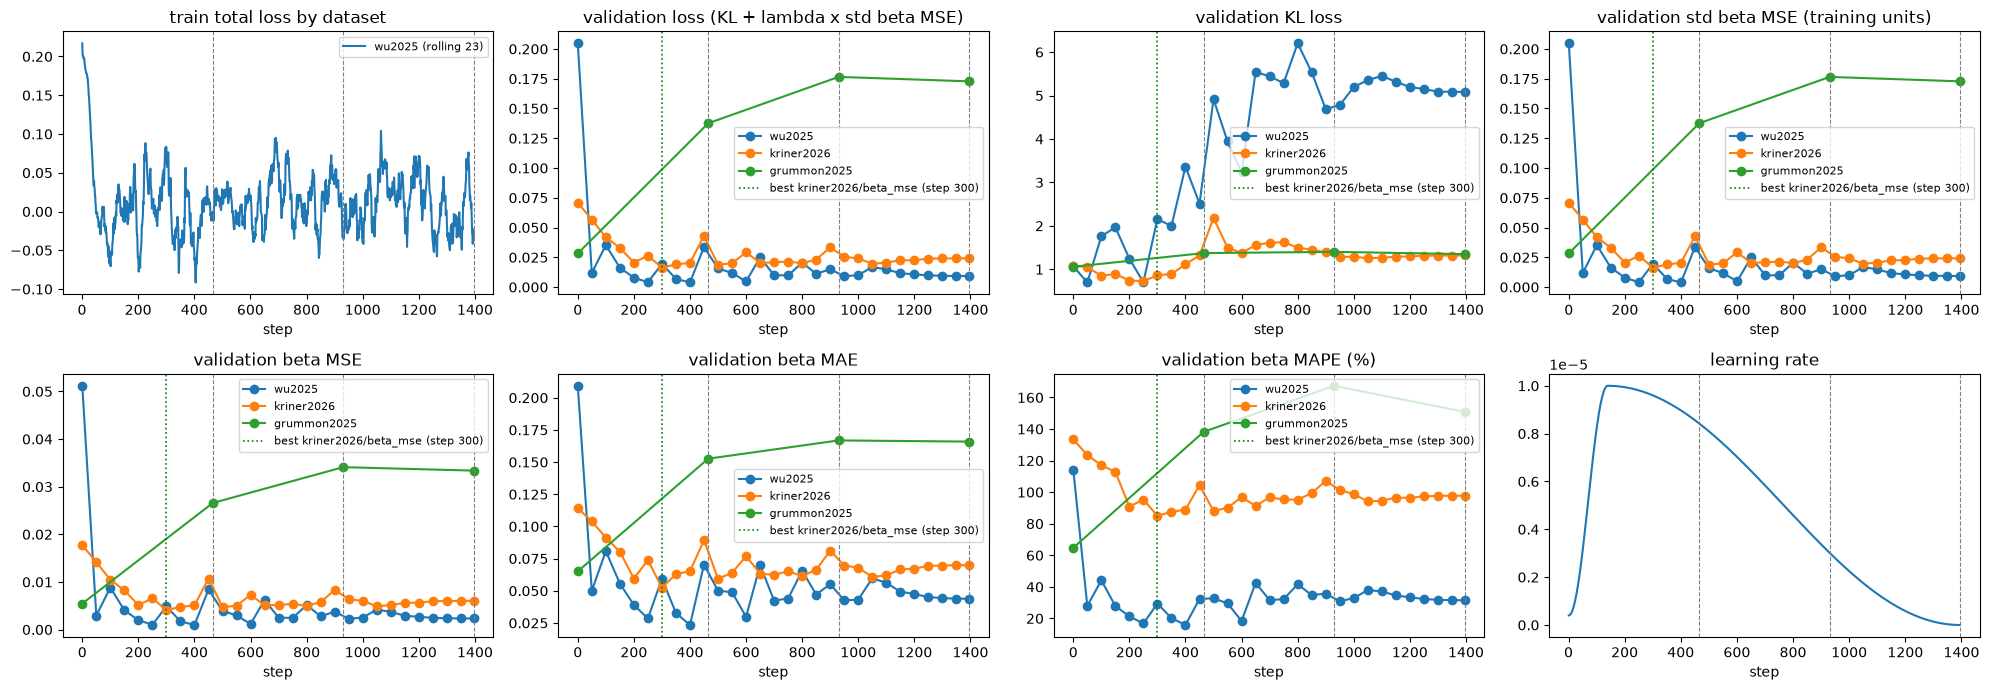

best.pt (step 300) validated at the end on: grummon2025


RunResult(config={'ce_datasets': [], 'beta_datasets': ['wu2025'], 'train_datasets': ['wu2025'], 'sample_size_by_dataset': {'wu2025': 40}, 'beta_lambda': 1.0, 'kl_anchor_alpha': 0.0, 'lr': 1e-05, 'num_epochs': 3, 'eval_every_by_validator': {'wu2025': 50, 'kriner2026': 50, 'grummon2025': 465}, 'lr_schedule': 'onecycle', 'weight_decay': 0.01, 'micro_chunk': 16, 'p0_chunk': 32, 'gradient_checkpointing': False, 'grad_clip': 1.0, 'seed': 42}, summary=label                 lambda=1*pop_beta(wu2025)
steps_per_epoch                             465
total_steps                                1395
rows_seen                                 55773
best_metric                 kriner2026/beta_mse
best_mode                                   min
best_step                                   300
best_value                             0.004098
mean_grad_norm                         4.486883
mean_step_ms                         814.009542
mean_ms_per_row                       22.118433
mean_eval_wall_sec     

In [16]:
train_kl_anchor_run(0.0)

## Run 2 — Light KL Anchor (`kl_anchor_alpha = 0.02`)

=== wu_table_alpha=0.02 (beta_lambda=1.0, kl_anchor_alpha=0.02, lr=1e-05, epochs=3) ===


,wu_table_alpha=0.02
ce_datasets,[]
beta_datasets,[wu2025]
train_datasets,[wu2025]
sample_size_by_dataset,{'wu2025': 40}
beta_lambda,1.0
kl_anchor_alpha,0.02
lr,0.00001
num_epochs,3
eval_every_by_validator,"{'wu2025': 50, 'kriner2026': 50, 'grummon2025'..."
lr_schedule,onecycle


,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,wu2025/eval_wall_sec,kriner2026/eval_wall_sec,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.20474,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,0.07099,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,0.02828,0.02828,1.05890,0.00546,0.06510,64.72026,0.50000,NaN,33.35836,10.81188,63.95903,0.00000
50,1,2000,0.08246,0.00847,0.00847,0.68075,0.00212,0.04175,23.21145,1.00000,0.05722,0.05722,1.04988,0.01430,0.10433,123.71561,-0.14685,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00000,33.47827,10.87055,NaN,137.42926
100,1,4000,-0.00248,0.03475,0.03475,0.87019,0.00869,0.07739,38.33355,1.00000,0.04778,0.04778,0.78882,0.01194,0.09550,113.15036,0.13986,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.20141,11.21563,NaN,178.05434
150,1,6000,0.02644,0.03650,0.03650,0.70489,0.00912,0.07315,36.02293,1.00000,0.04328,0.04328,0.77464,0.01082,0.09012,103.64643,0.16783,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.09421,11.07377,NaN,218.75511
200,1,8000,0.01101,0.00400,0.00400,0.65440,0.00100,0.02356,11.92099,0.97619,0.03721,0.03721,0.71524,0.00930,0.08472,100.11278,0.20979,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.13501,11.05508,NaN,259.47455
250,1,10000,0.03195,0.00311,0.00311,0.67113,0.00078,0.02366,12.69110,0.97619,0.03720,0.03720,0.74177,0.00930,0.08371,96.30818,0.27273,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.26885,11.08624,NaN,300.22321
300,1,12000,0.02876,0.00758,0.00758,0.86704,0.00189,0.03662,24.55790,1.00000,0.03402,0.03402,0.81285,0.00850,0.08087,93.66903,0.27972,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.14967,11.34572,NaN,340.93871
350,1,13991,0.00020,0.01016,0.01016,0.65339,0.00254,0.03937,17.74131,0.97619,0.03237,0.03237,0.70848,0.00809,0.07780,88.91885,0.51049,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.38730,11.38168,NaN,381.61505
400,1,15991,0.01320,0.00206,0.00206,0.64489,0.00052,0.01856,11.46219,1.00000,0.02933,0.02933,0.69426,0.00733,0.07547,89.32823,0.55245,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.25154,11.08034,NaN,422.27303


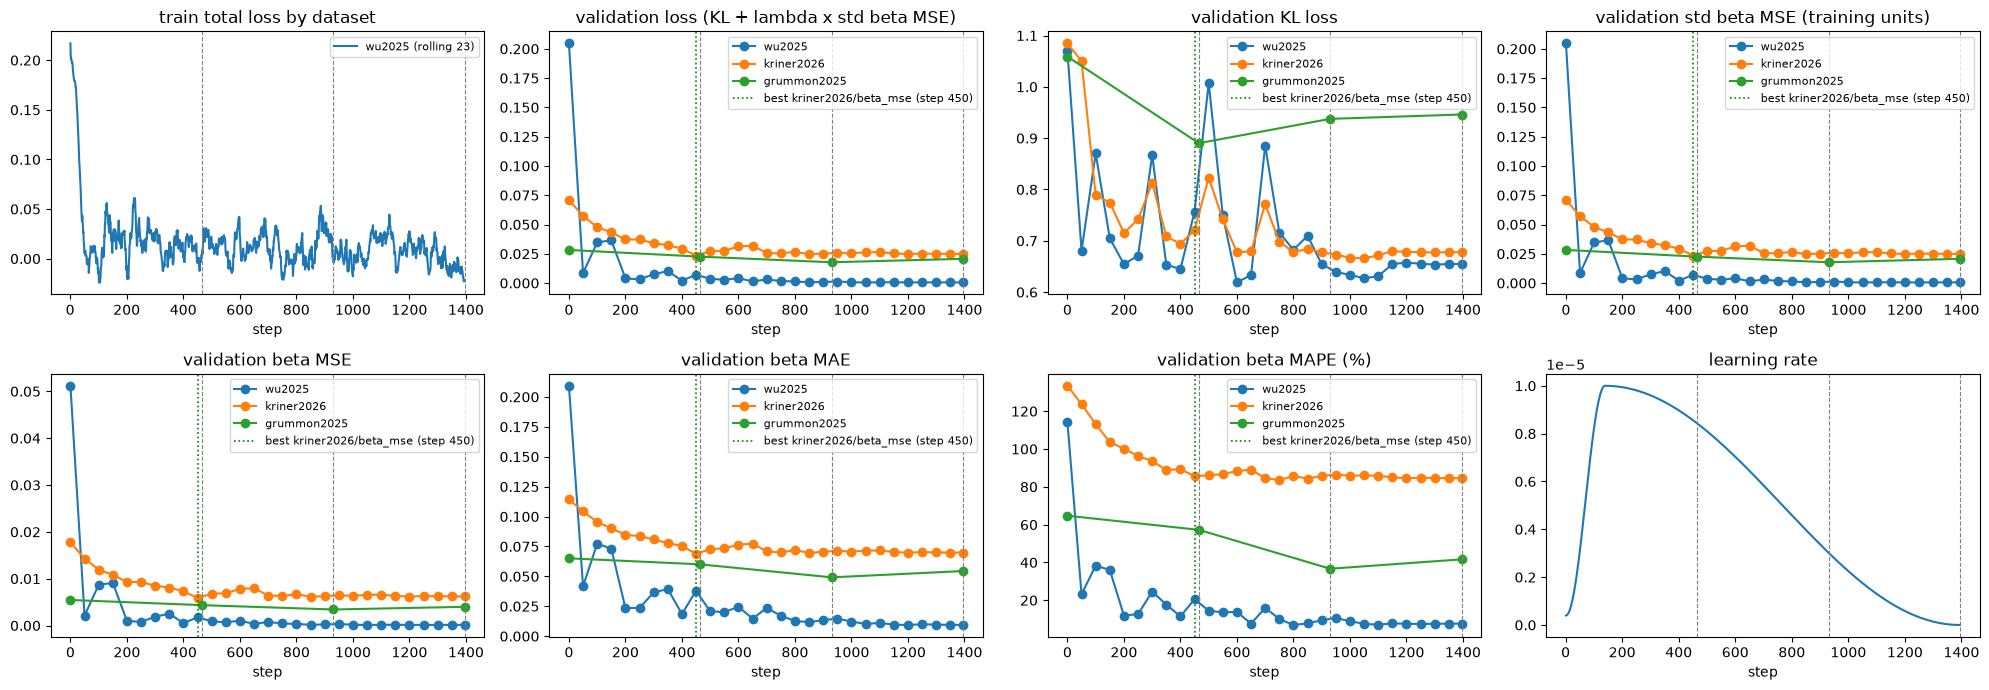

best.pt (step 450) validated at the end on: grummon2025


RunResult(config={'ce_datasets': [], 'beta_datasets': ['wu2025'], 'train_datasets': ['wu2025'], 'sample_size_by_dataset': {'wu2025': 40}, 'beta_lambda': 1.0, 'kl_anchor_alpha': 0.02, 'lr': 1e-05, 'num_epochs': 3, 'eval_every_by_validator': {'wu2025': 50, 'kriner2026': 50, 'grummon2025': 465}, 'lr_schedule': 'onecycle', 'weight_decay': 0.01, 'micro_chunk': 16, 'p0_chunk': 32, 'gradient_checkpointing': False, 'grad_clip': 1.0, 'seed': 42}, summary=label                 lambda=1*pop_beta(wu2025)+alpha=0.02*KL_p0
steps_per_epoch                                              465
total_steps                                                 1395
rows_seen                                                  55773
best_metric                                  kriner2026/beta_mse
best_mode                                                    min
best_step                                                    450
best_value                                              0.005854
mean_grad_norm                

In [17]:
train_kl_anchor_run(0.02)

## Run 3 — Moderate KL Anchor (`kl_anchor_alpha = 0.1`)

=== wu_table_alpha=0.1 (beta_lambda=1.0, kl_anchor_alpha=0.1, lr=1e-05, epochs=3) ===


,wu_table_alpha=0.1
ce_datasets,[]
beta_datasets,[wu2025]
train_datasets,[wu2025]
sample_size_by_dataset,{'wu2025': 40}
beta_lambda,1.0
kl_anchor_alpha,0.1
lr,0.00001
num_epochs,3
eval_every_by_validator,"{'wu2025': 50, 'kriner2026': 50, 'grummon2025'..."
lr_schedule,onecycle


,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,wu2025/eval_wall_sec,kriner2026/eval_wall_sec,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.20474,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,0.07099,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,0.02828,0.02828,1.05890,0.00546,0.06510,64.72026,0.50000,NaN,33.35836,10.81188,63.95903,0.00000
50,1,2000,0.09481,0.00286,0.00286,0.71636,0.00072,0.02242,17.63646,0.97619,0.05917,0.05917,1.07271,0.01479,0.10551,123.96190,-0.13287,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00000,34.58282,11.41723,NaN,138.02200
100,1,4000,0.03029,0.00365,0.00365,0.58104,0.00091,0.02581,15.77377,0.97619,0.05194,0.05194,0.87168,0.01299,0.09854,113.86107,0.05594,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.46650,11.34801,NaN,178.65494
150,1,6000,0.04461,0.00483,0.00483,0.60225,0.00121,0.02688,14.96179,0.97619,0.04394,0.04394,0.80114,0.01098,0.09082,104.12786,0.14685,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.46828,11.23999,NaN,219.30915
200,1,8000,0.01730,0.01547,0.01547,0.59713,0.00387,0.04917,26.45496,0.97619,0.04405,0.04405,0.73392,0.01101,0.09031,102.74505,0.17483,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.18986,11.10397,NaN,260.07102
250,1,10000,0.04368,0.00577,0.00577,0.68736,0.00144,0.03422,25.50261,0.97619,0.03788,0.03788,0.76668,0.00947,0.08480,97.69622,0.24476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.53316,11.50285,NaN,300.82972
300,1,12000,0.03508,0.01204,0.01204,0.88851,0.00301,0.04703,28.31276,0.97619,0.03495,0.03495,0.79356,0.00874,0.08164,93.96087,0.38462,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.62604,11.57813,NaN,341.61085
350,1,13991,0.01598,0.00861,0.00861,0.64434,0.00215,0.03692,18.84882,0.97619,0.03531,0.03531,0.70794,0.00883,0.08088,91.83903,0.51748,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.63131,11.54798,NaN,382.23472
400,1,15991,0.02655,0.00382,0.00382,0.71430,0.00095,0.02494,17.99058,0.97619,0.03145,0.03145,0.73706,0.00786,0.07778,90.44756,0.49650,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.12850,10.86513,NaN,423.03830


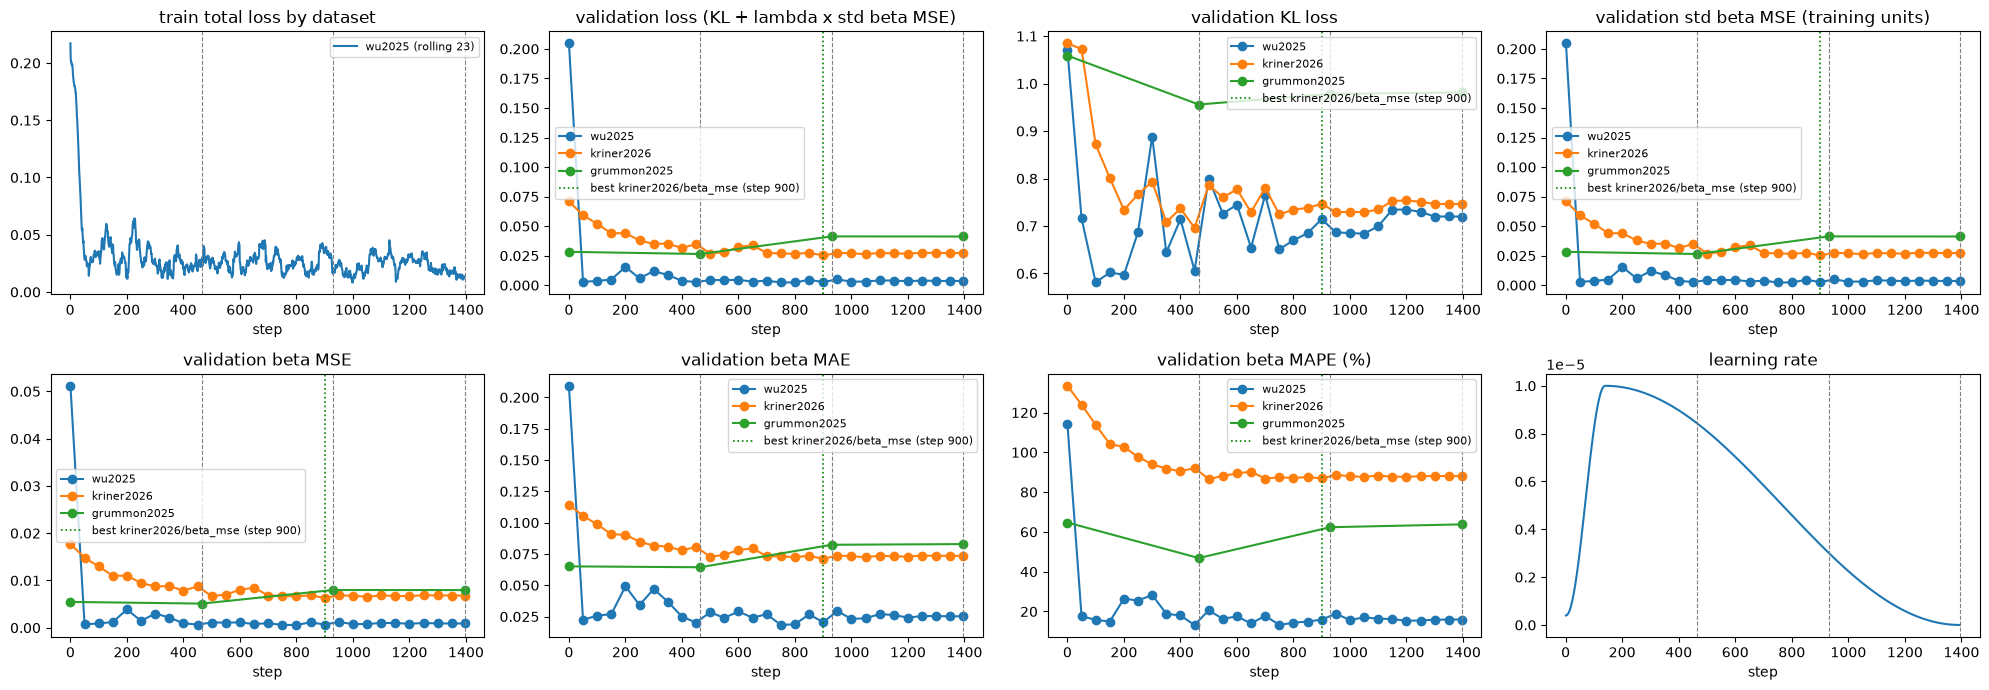

best.pt (step 900) validated at the end on: grummon2025


RunResult(config={'ce_datasets': [], 'beta_datasets': ['wu2025'], 'train_datasets': ['wu2025'], 'sample_size_by_dataset': {'wu2025': 40}, 'beta_lambda': 1.0, 'kl_anchor_alpha': 0.1, 'lr': 1e-05, 'num_epochs': 3, 'eval_every_by_validator': {'wu2025': 50, 'kriner2026': 50, 'grummon2025': 465}, 'lr_schedule': 'onecycle', 'weight_decay': 0.01, 'micro_chunk': 16, 'p0_chunk': 32, 'gradient_checkpointing': False, 'grad_clip': 1.0, 'seed': 42}, summary=label                 lambda=1*pop_beta(wu2025)+alpha=0.1*KL_p0
steps_per_epoch                                             465
total_steps                                                1395
rows_seen                                                 55773
best_metric                                 kriner2026/beta_mse
best_mode                                                   min
best_step                                                   900
best_value                                             0.006293
mean_grad_norm                         

In [18]:
train_kl_anchor_run(0.1)

## Run 4 — Strong KL Anchor (`kl_anchor_alpha = 0.5`)

=== wu_table_alpha=0.5 (beta_lambda=1.0, kl_anchor_alpha=0.5, lr=1e-05, epochs=3) ===


,wu_table_alpha=0.5
ce_datasets,[]
beta_datasets,[wu2025]
train_datasets,[wu2025]
sample_size_by_dataset,{'wu2025': 40}
beta_lambda,1.0
kl_anchor_alpha,0.5
lr,0.00001
num_epochs,3
eval_every_by_validator,"{'wu2025': 50, 'kriner2026': 50, 'grummon2025'..."
lr_schedule,onecycle


,epoch,rows_seen,train_loss,wu2025/val_loss,wu2025/std_beta_mse,wu2025/kl_loss,wu2025/beta_mse,wu2025/beta_mae,wu2025/beta_mape_pct,wu2025/spearman_rho,kriner2026/val_loss,kriner2026/std_beta_mse,kriner2026/kl_loss,kriner2026/beta_mse,kriner2026/beta_mae,kriner2026/beta_mape_pct,kriner2026/spearman_rho,grummon2025/val_loss,grummon2025/std_beta_mse,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,wu2025/eval_wall_sec,kriner2026/eval_wall_sec,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,0,NaN,0.20474,0.20474,1.06998,0.05118,0.20927,114.14264,-0.21429,0.07099,0.07099,1.08483,0.01775,0.11425,133.43868,-0.26573,0.02828,0.02828,1.05890,0.00546,0.06510,64.72026,0.50000,NaN,33.35836,10.81188,63.95903,0.00000
50,1,2000,0.12459,0.03662,0.03662,0.81494,0.00915,0.08128,46.89165,0.97619,0.06286,0.06286,1.06723,0.01571,0.10846,127.68650,-0.24476,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00000,33.72777,10.77574,NaN,137.79060
100,1,4000,0.07710,0.01457,0.01457,0.64022,0.00364,0.04724,31.92740,0.97619,0.05624,0.05624,0.90383,0.01406,0.10273,120.62019,-0.06294,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.65006,10.78904,NaN,178.46728
150,1,6000,0.08357,0.02015,0.02015,0.71484,0.00504,0.05749,34.18863,0.95238,0.04866,0.04866,0.83560,0.01217,0.09551,110.33391,0.05594,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.75329,10.67588,NaN,219.10631
200,1,8000,0.06779,0.02959,0.02959,0.73272,0.00740,0.06906,34.83963,0.97619,0.05017,0.05017,0.80706,0.01254,0.09586,108.76672,0.04196,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.68859,10.84991,NaN,259.85081
250,1,10000,0.07674,0.01714,0.01714,0.70334,0.00428,0.05618,41.62030,0.95238,0.04541,0.04541,0.78817,0.01135,0.09209,106.18402,0.15385,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.05173,10.97432,NaN,300.61759
300,1,12000,0.07866,0.03002,0.03002,0.79505,0.00750,0.07335,44.03417,0.97619,0.04483,0.04483,0.79941,0.01121,0.09141,104.69343,0.13287,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.94394,10.80317,NaN,341.42325
350,1,13991,0.06434,0.02745,0.02745,0.74635,0.00686,0.06730,35.98398,0.95238,0.04300,0.04300,0.75894,0.01075,0.08952,102.63366,0.16084,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,34.11078,11.41115,NaN,381.87059
400,1,15991,0.06940,0.02084,0.02084,0.78624,0.00521,0.05890,35.81342,0.97619,0.04325,0.04325,0.78621,0.01081,0.08970,102.52299,0.14685,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00001,33.87138,10.67054,NaN,422.80316


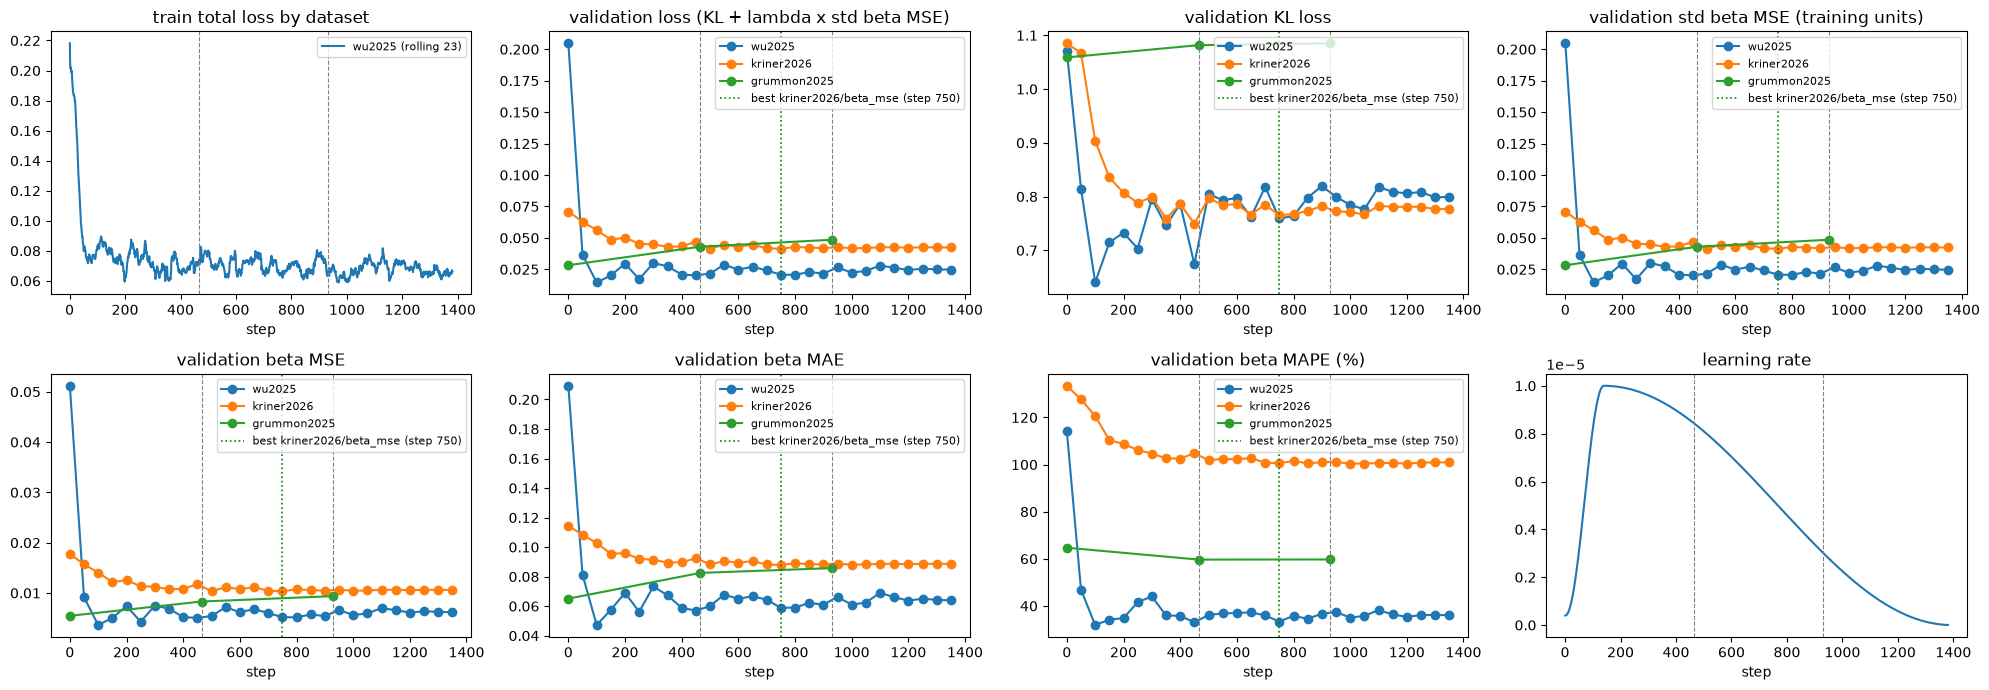

KeyboardInterrupt: 

In [19]:
train_kl_anchor_run(0.5)

# 4. Comparison Table & Optimization Diagnostics (`runs/kl_anchor_800m/`)

Reads directly from disk (requires only Cell 1 imports, so it can be run on CPU while or after training finishes). Compares both **`best.pt` (selected by `kriner2026/beta_mse`)** and **final-step (`step 1,395`) stability** across $\alpha \in \{0.0, 0.02, 0.1, 0.5\}$.

In [ ]:
def _sign_acc(beta_df: pd.DataFrame) -> float:
    return float(np.mean(np.sign(beta_df["model_pop_beta"].to_numpy(dtype=float)) == np.sign(beta_df["human_pop_beta"].to_numpy(dtype=float))))


def summarize_kl_anchor_sweep(runs_dir: Path, alphas: tuple[float, ...] = ALPHA_SWEEP) -> pd.DataFrame:
    runs_dir = Path(runs_dir)
    validators_pair = ("kriner2026", "grummon2025")
    first_existing = next((runs_dir / alpha_slug(a) for a in alphas if (runs_dir / alpha_slug(a) / "run.json").exists()), None)
    rows = []

    if first_existing is not None:
        base_info = extract_step0_from_run_dir(first_existing, validators_pair)
        m0 = base_info["metrics"]
        rows.append(
            {
                "slug": "step0_untrained_base",
                "kl_alpha": float("nan"),
                "status": "cached_step0",
                "best_step": 0,
                "last_step": 0,
                "kriner_best_mse": m0["kriner2026/beta_mse"],
                "kriner_best_rho": m0["kriner2026/spearman_rho"],
                "kriner_best_kl": m0["kriner2026/kl_loss"],
                "grummon_best_mse": m0["grummon2025/beta_mse"],
                "grummon_best_rho": m0["grummon2025/spearman_rho"],
                "grummon_best_sign": m0["grummon2025/sign_acc"],
                "grummon_best_kl": m0["grummon2025/kl_loss"],
                "kriner_final_mse": m0["kriner2026/beta_mse"],
                "grummon_final_mse": m0["grummon2025/beta_mse"],
                "wu_cross_last15": float("nan"),
                "wu_kl_p0_last15": 0.0,
                "wu_sample_mse_last15": float("nan"),
            }
        )

    for alpha in alphas:
        slug = alpha_slug(alpha)
        run_dir = runs_dir / slug
        if not (run_dir / "run.json").exists():
            rows.append({"slug": slug, "kl_alpha": alpha, "status": "not_run_yet"})
            continue
        run_json = run_store.read_run_json(run_dir)
        res = load_paper_run(run_dir)
        last_val_step = int(res.val_history_df.index[-1])
        last_val_row = res.val_history_df.loc[last_val_step]
        wu_ds = res.per_dataset_df.loc["wu2025"] if "wu2025" in res.per_dataset_df.index else None
        grummon_sign = _sign_acc(res.best_validation["grummon2025"][1]) if "grummon2025" in res.best_validation else float("nan")
        rows.append(
            {
                "slug": slug,
                "kl_alpha": alpha,
                "status": run_json["status"],
                "best_step": int(res.best["step"]),
                "last_step": int(res.step_df["step"].max()) if len(res.step_df) > 0 else 0,
                "kriner_best_mse": float(res.best_row["kriner2026/beta_mse"]),
                "kriner_best_rho": float(res.best_row["kriner2026/spearman_rho"]),
                "kriner_best_kl": float(res.best_row["kriner2026/kl_loss"]),
                "grummon_best_mse": float(res.best_row["grummon2025/beta_mse"]),
                "grummon_best_rho": float(res.best_row["grummon2025/spearman_rho"]),
                "grummon_best_sign": grummon_sign,
                "grummon_best_kl": float(res.best_row["grummon2025/kl_loss"]),
                "kriner_final_mse": float(last_val_row["kriner2026/beta_mse"]),
                "grummon_final_mse": float(last_val_row["grummon2025/beta_mse"]),
                "wu_cross_last15": float(wu_ds["cross_loss_last15pct"]) if wu_ds is not None else float("nan"),
                "wu_kl_p0_last15": float(wu_ds["kl_anchor_last15pct"]) if wu_ds is not None else float("nan"),
                "wu_sample_mse_last15": float(wu_ds["sample_beta_mse_last15pct"]) if wu_ds is not None else float("nan"),
            }
        )
    return pd.DataFrame(rows).set_index("slug")


sweep_summary_df = summarize_kl_anchor_sweep(RUNS_DIR)
display(sweep_summary_df.round(5))

In [ ]:
available_runs = [
    (alpha, load_paper_run(RUNS_DIR / alpha_slug(alpha)))
    for alpha in ALPHA_SWEEP
    if (RUNS_DIR / alpha_slug(alpha) / "run.json").exists()
]

if not available_runs:
    print(f"No runs saved in {RUNS_DIR} yet.")
else:
    fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
    rolling_window = 30

    for alpha, res in available_runs:
        label = f"alpha={alpha:g} (best@{int(res.best['step'])})"
        st = res.step_df
        vh = res.val_history_df

        if len(st) > 0:
            axes[0, 0].plot(st["step"], st["cross_loss"].rolling(rolling_window, min_periods=1).mean(), linewidth=1.6, label=label)
            axes[0, 1].plot(st["step"], st["kl_anchor_loss"].rolling(rolling_window, min_periods=1).mean(), linewidth=1.6, label=label)
            axes[0, 2].plot(st["step"], st["sample_beta_mse"].rolling(rolling_window, min_periods=1).mean(), linewidth=1.6, label=label)

        for ax, col in (
            (axes[1, 0], "kriner2026/beta_mse"),
            (axes[1, 1], "grummon2025/beta_mse"),
            (axes[1, 2], "grummon2025/kl_loss"),
        ):
            series = vh[col].dropna()
            ax.plot(series.index, series.values, marker="o", markersize=3.5, linewidth=1.6, label=label)

    step0_vh = available_runs[0][1].val_history_df.loc[0]
    axes[1, 0].axhline(float(step0_vh["kriner2026/beta_mse"]), color="gray", linestyle="--", linewidth=1.0, label="Step 0 base")
    axes[1, 1].axhline(float(step0_vh["grummon2025/beta_mse"]), color="gray", linestyle="--", linewidth=1.0, label="Step 0 base")
    axes[1, 2].axhline(float(step0_vh["grummon2025/kl_loss"]), color="gray", linestyle="--", linewidth=1.0, label="Step 0 base")

    titles = [
        (axes[0, 0], "Wu 2025 Split Cross-Loss (30-step mean)"),
        (axes[0, 1], "Wu 2025 Forward KL(p0 || p) Drift (30-step mean)"),
        (axes[0, 2], "Wu 2025 Sample Beta MSE Variance (30-step mean)"),
        (axes[1, 0], "Kriner 2026 Beta MSE (Validation Selection)"),
        (axes[1, 1], "Grummon 2025 Beta MSE (Held-Out Test)"),
        (axes[1, 2], "Grummon 2025 Human KL (Held-Out Calibration)"),
    ]
    for ax, title in titles:
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("Optimization Step")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

    fig.tight_layout()
    plt.show()